# Cleaning & EDA — Review Shopee Indonesia (Google Play Store)

Notebook ini menangani:
1. Data cleaning dasar (dedup, missing value, filter review pendek, normalisasi ringan, filter bahasa)
2. Exploratory Data Analysis (EDA)

Output cleaning disimpan ke `data/processed/shopee_reviews_clean.csv` untuk dipakai di tahap LLM labeling berikutnya.

## 0. Import Library

In [ ]:
import pandas as pd
import numpy as np
import re
import matplotlib.pyplot as plt
import seaborn as sns
from langdetect import detect, DetectorFactory
from wordcloud import WordCloud
from collections import Counter
import json

DetectorFactory.seed = 42  # supaya hasil langdetect konsisten
sns.set_style("whitegrid")
%matplotlib inline


In [ ]:
import pandas as pd

df = pd.read_csv("data/raw/shopee_reviews_raw.csv")
df["at"] = pd.to_datetime(df["at"])

# hitung rata-rata review per hari
date_range_days = (df["at"].max() - df["at"].min()).days
avg_per_day = len(df) / date_range_days

print(f"Rentang tanggal: {df['at'].min()} s.d. {df['at'].max()}")
print(f"Jumlah hari     : {date_range_days}")
print(f"Rata-rata review/hari: {avg_per_day:.0f}")

Kalau `langdetect` atau `wordcloud` belum terinstall, jalankan cell berikut sekali saja.

In [ ]:
# !pip install langdetect wordcloud --quiet


## 1. Load Data Mentah

In [ ]:
RAW_PATH = "../data/raw/shopee_reviews_raw.csv"
PROCESSED_PATH = "../data/processed/shopee_reviews_clean.csv"

df = pd.read_csv(RAW_PATH)
print(f"Jumlah baris awal: {len(df)}")
df.head()


Jumlah baris awal: 10000


,reviewId,content,score,thumbsUpCount,at,appVersion,reviewCreatedVersion
0,5585bdec-26f8-4e05-9380-a5156310b7e8,good job,5,0,2026-09-04 14:51:15,NaN,NaN
1,2d900116-95db-4727-9377-d92f4d774d3b,aplikasi k*ntol iklan nya maksa bngt anjg gua ...,1,8,2026-09-04 12:30:16,3.81.32,3.81.32
2,7abb8dbf-a85c-4745-ac89-240b34b06188,mantap pokonamah,5,1,2026-09-02 20:23:49,NaN,NaN
3,5736f990-1306-4c0e-983b-3a5a9b131652,terus kembangkan dan lebih di permudah,5,0,2026-08-29 18:26:44,3.81.30,3.81.30
4,181fa0b5-15f4-4936-aea5-fd92651ce800,"sjopee sekarang paling mantap,",5,2,2026-08-29 18:26:18,3.38.34,3.38.34


In [ ]:
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 7 columns):
 #   Column                Non-Null Count  Dtype
---  ------                --------------  -----
 0   reviewId              10000 non-null  str  
 1   content               10000 non-null  str  
 2   score                 10000 non-null  int64
 3   thumbsUpCount         10000 non-null  int64
 4   at                    10000 non-null  str  
 5   appVersion            7668 non-null   str  
 6   reviewCreatedVersion  7668 non-null   str  
dtypes: int64(2), str(5)
memory usage: 547.0 KB


## 2. EDA — Sebelum Cleaning

Lihat kondisi data mentah dulu sebelum dibersihkan, supaya kita tahu apa saja yang perlu ditangani.

### 2.1 Missing Value

In [ ]:
missing_summary = df.isnull().sum().to_frame("missing_count")
missing_summary["missing_pct"] = (missing_summary["missing_count"] / len(df) * 100).round(2)
missing_summary


,missing_count,missing_pct
reviewId,0,0.00
content,0,0.00
score,0,0.00
thumbsUpCount,0,0.00
at,0,0.00
appVersion,2332,23.32
reviewCreatedVersion,2332,23.32


### 2.2 Distribusi Rating (score)

C:\Users\HP\AppData\Local\Temp\ipykernel_11556\371108002.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x="score", palette="viridis")


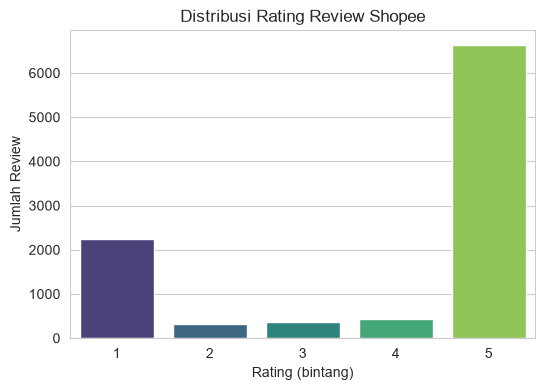

score
5    66.4
1    22.5
4     4.4
3     3.6
2     3.2
Name: proportion, dtype: float64


In [ ]:
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="score", palette="viridis")
plt.title("Distribusi Rating Review Shopee")
plt.xlabel("Rating (bintang)")
plt.ylabel("Jumlah Review")
plt.show()

print(df["score"].value_counts(normalize=True).round(3) * 100)


### 2.3 Distribusi Panjang Review (jumlah kata)

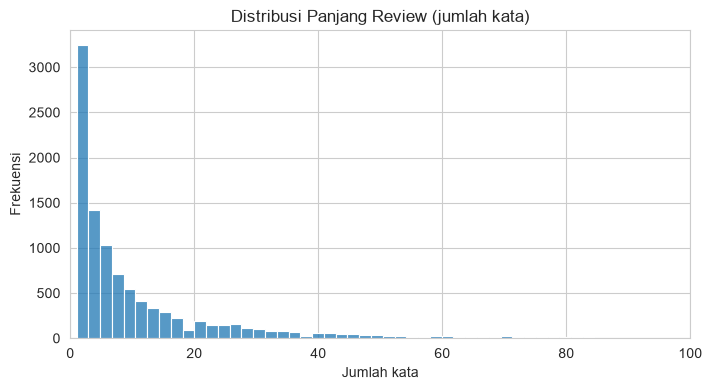

count    10000.000000
mean        10.728400
std         14.216485
min          1.000000
25%          2.000000
50%          5.000000
75%         13.000000
max         96.000000
Name: word_count, dtype: float64


In [ ]:
df["word_count"] = df["content"].astype(str).apply(lambda x: len(x.split()))

plt.figure(figsize=(8, 4))
sns.histplot(df["word_count"], bins=50, kde=False)
plt.title("Distribusi Panjang Review (jumlah kata)")
plt.xlabel("Jumlah kata")
plt.ylabel("Frekuensi")
plt.xlim(0, 100)
plt.show()

print(df["word_count"].describe())


### 2.4 Volume Review dari Waktu ke Waktu

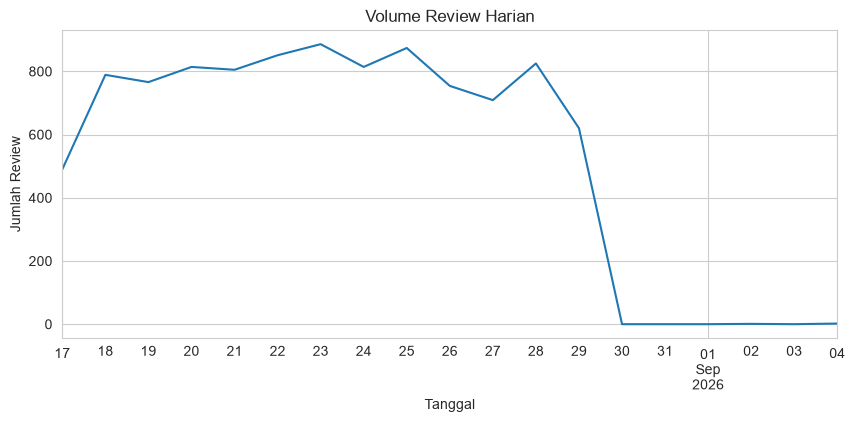

In [ ]:
df["at"] = pd.to_datetime(df["at"], errors="coerce")
df_by_date = df.set_index("at").resample("D").size()

plt.figure(figsize=(10, 4))
df_by_date.plot()
plt.title("Volume Review Harian")
plt.xlabel("Tanggal")
plt.ylabel("Jumlah Review")
plt.show()


### 2.5 Duplikat

In [ ]:
dup_count = df.duplicated(subset=["reviewId"]).sum()
dup_content_count = df.duplicated(subset=["content"]).sum()
print(f"Duplikat berdasarkan reviewId : {dup_count}")
print(f"Duplikat berdasarkan content  : {dup_content_count}")


Duplikat berdasarkan reviewId : 0
Duplikat berdasarkan content  : 2204


## 3. Data Cleaning

### 3.1 Hapus Duplikat

In [ ]:
before = len(df)
df = df.drop_duplicates(subset=["reviewId"])
df = df.drop_duplicates(subset=["content"])
after = len(df)
print(f"Baris sebelum: {before} -> sesudah dedup: {after} (dihapus: {before - after})")


Baris sebelum: 10000 -> sesudah dedup: 7796 (dihapus: 2204)


### 3.2 Handle Missing Value

Kolom `appVersion` dan `reviewCreatedVersion` boleh kosong (tidak dipakai untuk modeling), cukup diisi placeholder. Baris dengan `content` kosong dibuang karena tidak bisa dipakai sama sekali.

In [ ]:
before = len(df)
df = df.dropna(subset=["content"])
df["content"] = df["content"].astype(str).str.strip()
df = df[df["content"] != ""]
after = len(df)
print(f"Baris sebelum: {before} -> sesudah buang content kosong: {after}")

df["appVersion"] = df["appVersion"].fillna("unknown")
df["reviewCreatedVersion"] = df["reviewCreatedVersion"].fillna("unknown")


Baris sebelum: 7796 -> sesudah buang content kosong: 7796


### 3.3 Filter Review Terlalu Pendek

Review seperti "good job", "uhuyy", "mantap" tidak memberi insight aspek apa pun. Buang review dengan jumlah kata di bawah threshold (default: 3 kata).

In [ ]:
MIN_WORD_COUNT = 3

before = len(df)
df["word_count"] = df["content"].apply(lambda x: len(x.split()))
df = df[df["word_count"] >= MIN_WORD_COUNT]
after = len(df)
print(f"Baris sebelum: {before} -> sesudah filter review pendek (< {MIN_WORD_COUNT} kata): {after}")


Baris sebelum: 7796 -> sesudah filter review pendek (< 3 kata): 6685


### 3.4 Normalisasi Ringan

Catatan: normalisasi di sini SENGAJA ringan (bukan stemming/stopword removal), karena teks akan dikirim ke LLM untuk labeling dan nantinya diproses IndoBERT — keduanya butuh konteks kalimat utuh.

In [ ]:
def normalize_text(text: str) -> str:
    text = text.strip()

    # kurangi elongasi karakter berlebihan (mis. "bangeeeet" -> "bangeet")
    text = re.sub(r"(.)\1{2,}", r"\1\1", text)

    # hapus karakter non-standar berulang (mis. simbol spam "!!!!!!" -> "!!!")
    text = re.sub(r"([!?.,])\1{2,}", r"\1\1\1", text)

    # rapikan whitespace berlebihan
    text = re.sub(r"\s+", " ", text)

    return text.strip()


df["content_clean"] = df["content"].apply(normalize_text)
df[["content", "content_clean"]].sample(5, random_state=42)


,content,content_clean
4615,pelayanan yg menyenangkan dan banyak produkt y...,pelayanan yg menyenangkan dan banyak produkt y...
4195,"mohon pihak aplikasi,jika akun kita terhapus,d...","mohon pihak aplikasi,jika akun kita terhapus,d..."
2186,"saya sangat benci dengan aplikasi ini, iklan n...","saya sangat benci dengan aplikasi ini, iklan n..."
8871,"yth admin Shopee, mohon dibaca pesan saya ini,...","yth admin Shopee, mohon dibaca pesan saya ini,..."
9099,shopee sekarang pengiriman sangat sangat lamba...,shopee sekarang pengiriman sangat sangat lambatt


### 3.4b Normalisasi Slang (Kamus)

Menggunakan dua kamus normalisasi bahasa gaul/slang Indonesia:
- `combined_slang_words.txt` — JSON, ±1000 pasangan slang -> formal
- `colloquial-indonesian-lexicon.csv` — ±15.000 baris, kolom `slang`, `formal`, `category1` (jenis fenomena kebahasaan)

Kedua file ini digabung jadi satu lookup table dan diterapkan **sebelum** deteksi bahasa — supaya singkatan seperti "krn", "dg", "bgt" dinormalisasi ke bentuk baku ("karena", "dengan", "banget") dulu, sehingga `langdetect` tidak salah deteksi bahasa karena pola karakter yang tidak umum.

In [ ]:
SLANG_TXT_PATH = "../data/external/combined_slang_words.txt"
SLANG_CSV_PATH = "../data/external/colloquial-indonesian-lexicon.csv"

with open(SLANG_TXT_PATH, "r", encoding="utf-8") as f:
    slang_dict_txt = json.load(f)

slang_df = pd.read_csv(SLANG_CSV_PATH)

# satu slang bisa muncul di beberapa baris (beda context) -> ambil pemetaan formal pertama saja
slang_df_unique = slang_df.drop_duplicates(subset="slang", keep="first")
slang_dict_csv = dict(
    zip(slang_df_unique["slang"].astype(str).str.lower(), slang_df_unique["formal"].astype(str))
)

# gabungkan dua kamus - versi txt dianggap lebih terkurasi, jadi override kalau ada duplikat key
combined_slang_dict = {**slang_dict_csv, **{k.lower(): v for k, v in slang_dict_txt.items()}}

print(f"Jumlah entri kamus dari txt : {len(slang_dict_txt)}")
print(f"Jumlah entri kamus dari csv : {len(slang_dict_csv)}")
print(f"Total entri kamus gabungan  : {len(combined_slang_dict)}")


Jumlah entri kamus dari txt : 1020
Jumlah entri kamus dari csv : 4331
Total entri kamus gabungan  : 5044


In [ ]:
def normalize_slang(text: str, slang_dict: dict) -> str:
    """Ganti tiap token yang cocok dengan kamus slang -> bentuk formal.
    Tanda baca tetap dipertahankan sebagai token terpisah."""
    tokens = re.findall(r"\w+|[^\w\s]", text, re.UNICODE)
    normalized = [slang_dict.get(tok.lower(), tok) for tok in tokens]
    joined = " ".join(normalized)
    # rapikan spasi berlebih sebelum tanda baca (mis. "bagus ." -> "bagus.")
    joined = re.sub(r"\s+([.,!?;:])", r"\1", joined)
    joined = re.sub(r"\s+", " ", joined)
    return joined.strip()


# terapkan ke content_clean (menimpa/melanjutkan hasil normalisasi ringan sebelumnya)
df["content_clean"] = df["content_clean"].apply(lambda x: normalize_slang(x, combined_slang_dict))

df[["content", "content_clean"]].sample(5, random_state=42)


,content,content_clean
4615,pelayanan yg menyenangkan dan banyak produkt y...,pelayanan yang menyenangkan dan banyak produkt...
4195,"mohon pihak aplikasi,jika akun kita terhapus,d...","mohon pihak aplikasi, jika akun kita terhapus,..."
2186,"saya sangat benci dengan aplikasi ini, iklan n...","saya sangat benci dengan aplikasi ini, iklan n..."
8871,"yth admin Shopee, mohon dibaca pesan saya ini,...","yth admin Shopee, mohon dibaca pesan saya ini,..."
9099,shopee sekarang pengiriman sangat sangat lamba...,shopee sekarang pengiriman sangat sangat lambatt


> Cek beberapa contoh di atas — pastikan kata seperti "bgt", "krn", "dg", "udah" sudah berubah jadi bentuk baku. Kalau ada kata yang belum tertangkap kamus, itu wajar (kamus tidak akan 100% lengkap) — cukup lanjut ke tahap berikutnya, sisanya akan tetap bisa dipahami LLM maupun IndoBERT.

In [ ]:
df[["content", "content_clean"]].sample(10)

,content,content_clean
3334,baguss aku sukaaaaaaa,bagus aku suka
1238,aku gak suka sama aplikasi ini sok alnya suka ...,aku enggak suka sama aplikasi ini sok alnya su...
9820,ntah knp ni apk msah gkk bisa COD Padahal kate...,entah kenapa ini apk msah enggak bisa COD Pada...
2828,bagus sih cuman iklannya itu loh ngeselin,bagus sih cuman iklannya itu loh mengesalkan
8515,"Saya mengikuti shopi imdonesia, supaya saya bi...","Saya mengikuti shopi imdonesia, supaya saya bi..."
5639,shopee sangat membantu sekali. good,shopee sangat membantu sekali. good
316,"Tolong lah pihak Shopee, jngan dikit² kena bal...","Tolong lah pihak Shopee, jangan dikit² kena ba..."
391,barang cepat sampai dan kurir y ramah,barang cepat sampai dan kurir ya ramah
3114,sangat puas dengan aplikasih ini,sangat puas dengan aplikasih ini
125,Belanja di shopee aman dan amanah. Belanja di ...,Belanja di shopee aman dan amanah. Belanja di ...


### 3.5 Deteksi & Filter Bahasa

Buang review yang terdeteksi bukan bahasa Indonesia, supaya konsisten dengan model IndoBERT yang dipakai nanti.

In [ ]:
def safe_detect(text: str) -> str:
    try:
        return detect(text)
    except Exception:
        return "unknown"


df["detected_lang"] = df["content_clean"].apply(safe_detect)
df["detected_lang"].value_counts().head(10)


detected_lang
id         6176
tl          241
en           94
fi           21
et           18
af           16
so           14
de           14
sw           12
unknown       9
Name: count, dtype: int64

In [ ]:
before = len(df)
df_filtered = df[df["detected_lang"] == "id"].copy()
after = len(df_filtered)
print(f"Baris sebelum filter bahasa: {before} -> sesudah (hanya 'id'): {after}")
print(f"Dibuang: {before - after} baris ({(before - after) / before * 100:.1f}%)")

df = df_filtered


Baris sebelum filter bahasa: 6685 -> sesudah (hanya 'id'): 6176
Dibuang: 509 baris (7.6%)


In [ ]:
df.head()

,reviewId,content,score,thumbsUpCount,at,appVersion,reviewCreatedVersion,word_count,content_clean,detected_lang
1,2d900116-95db-4727-9377-d92f4d774d3b,aplikasi k*ntol iklan nya maksa bngt anjg gua ...,1,8,2026-09-04 12:30:16,3.81.32,3.81.32,32,aplikasi ke * ntol iklan nya maksa banget anjg...,id
3,5736f990-1306-4c0e-983b-3a5a9b131652,terus kembangkan dan lebih di permudah,5,0,2026-08-29 18:26:44,3.81.30,3.81.30,6,terus kembangkan dan lebih di permudah,id
4,181fa0b5-15f4-4936-aea5-fd92651ce800,"sjopee sekarang paling mantap,",5,2,2026-08-29 18:26:18,3.38.34,3.38.34,4,"sjopee sekarang paling mantap,",id
6,1ac3fcdf-4ee7-4522-80e9-0779c8cea6e9,iklan mu sangat menjijikan dan kamu sering mem...,1,8,2026-08-29 18:25:21,3.80.37,3.80.37,12,iklan mu sangat menjijikan dan kamu sering mem...,id
9,b7e72be3-e537-4ec3-8b18-a80f750ab125,"pengiriman lama sampai,bahkan barang yg di pes...",4,5,2026-08-29 18:22:19,3.81.30,3.81.30,31,"pengiriman lama sampai, bahkan barang yang di ...",id


> Catatan: `langdetect` bisa saja salah deteksi untuk teks yang sangat pendek atau campur kode (code-mixing). Kalau persentase yang terbuang cukup besar, cek dulu manual beberapa sample yang terbuang sebelum melanjutkan — bisa jadi ambang batas perlu disesuaikan.

## 4. EDA — Setelah Cleaning

Bandingkan kondisi data sebelum vs sesudah cleaning.

### 4.1 Distribusi Rating Setelah Cleaning

C:\Users\HP\AppData\Local\Temp\ipykernel_11556\533586238.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x="score", palette="viridis")


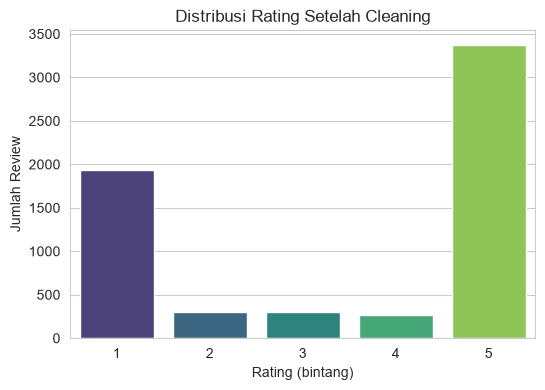

In [ ]:
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="score", palette="viridis")
plt.title("Distribusi Rating Setelah Cleaning")
plt.xlabel("Rating (bintang)")
plt.ylabel("Jumlah Review")
plt.show()


### 4.2 Distribusi Panjang Review Setelah Cleaning

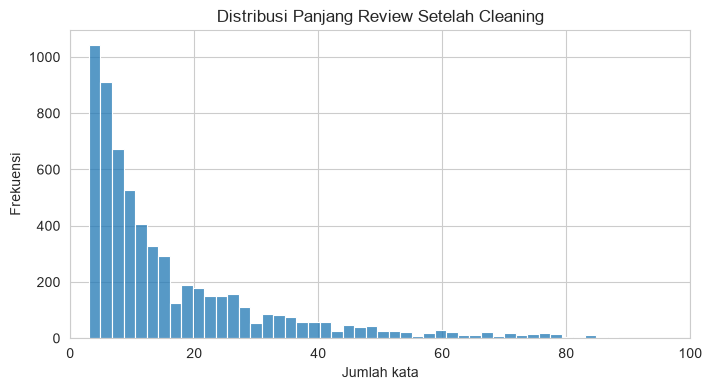

count    6176.000000
mean       16.177623
std        15.699115
min         3.000000
25%         6.000000
50%        10.000000
75%        21.000000
max        96.000000
Name: word_count, dtype: float64


In [ ]:
plt.figure(figsize=(8, 4))
sns.histplot(df["word_count"], bins=50, kde=False)
plt.title("Distribusi Panjang Review Setelah Cleaning")
plt.xlabel("Jumlah kata")
plt.ylabel("Frekuensi")
plt.xlim(0, 100)
plt.show()

print(df["word_count"].describe())


### 4.4 Kata yang Paling Sering Muncul di Review Rating Rendah

Ini jadi petunjuk awal untuk menentukan aspek di tahap topic modeling berikutnya.

In [ ]:
def get_top_words(text_series, top_n=20):
    all_words = " ".join(text_series).lower().split()
    # buang kata sangat umum yang tidak informatif (stopword minimal, bukan stopword removal penuh)
    basic_stopwords = {"yang", "dan", "di", "ke", "ini", "itu", "ada", "ya", "aja",
                        "juga", "untuk", "tidak", "dengan", "saya", "nya", "gak", "ga"}
    filtered = [w for w in all_words if w not in basic_stopwords and len(w) > 2]
    return Counter(filtered).most_common(top_n)


top_words_low = get_top_words(df[df["score"] <= 2]["content_clean"])
pd.DataFrame(top_words_low, columns=["word", "count"])


,word,count
0,enggak,1179
1,sudah,802
2,shopee,793
3,iklan,643
4,bisa,511
5,kalau,452
6,aplikasi,440
7,tapi,433
8,bahkan,364
9,barang,363


### 4.5 Volume Review Harian Setelah Cleaning

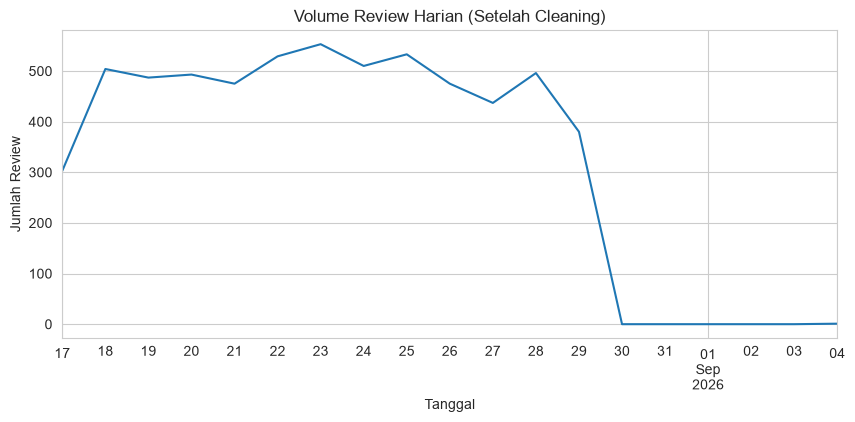

In [ ]:
df_by_date_clean = df.set_index("at").resample("D").size()

plt.figure(figsize=(10, 4))
df_by_date_clean.plot()
plt.title("Volume Review Harian (Setelah Cleaning)")
plt.xlabel("Tanggal")
plt.ylabel("Jumlah Review")
plt.show()


### 4.6 Ringkasan Sebelum vs Sesudah Cleaning

In [ ]:
summary = pd.DataFrame({
    "tahap": ["Raw", "Setelah cleaning"],
    "jumlah_review": [before if False else None, len(df)]  # placeholder, isi manual di bawah
})

# Ringkasan manual (isi ulang angka dari cell-cell sebelumnya sesuai hasil run kamu)
print("Ringkasan proses cleaning:")
print(f"- Jumlah review setelah cleaning final : {len(df)}")
print(f"- Rentang tanggal review               : {df['at'].min()} s.d. {df['at'].max()}")
print(f"- Rata-rata panjang review (kata)       : {df['word_count'].mean():.1f}")


Ringkasan proses cleaning:
- Jumlah review setelah cleaning final : 6176
- Rentang tanggal review               : 2026-08-17 12:50:15 s.d. 2026-09-04 12:30:16
- Rata-rata panjang review (kata)       : 16.2


## 5. Simpan Data Bersih

Data ini yang akan dipakai di tahap LLM labeling berikutnya.

In [ ]:
output_cols = ["reviewId", "content_clean", "score", "thumbsUpCount", "at", "appVersion"]
df_final = df[output_cols].rename(columns={"content_clean": "content"})

df_final.to_csv(PROCESSED_PATH, index=False)
print(f"Data bersih disimpan ke: {PROCESSED_PATH}")
print(f"Total baris final: {len(df_final)}")
df_final.head()


Data bersih disimpan ke: ../data/processed/shopee_reviews_clean.csv
Total baris final: 6176


,reviewId,content,score,thumbsUpCount,at,appVersion
1,2d900116-95db-4727-9377-d92f4d774d3b,aplikasi ke * ntol iklan nya maksa banget anjg...,1,8,2026-09-04 12:30:16,3.81.32
3,5736f990-1306-4c0e-983b-3a5a9b131652,terus kembangkan dan lebih di permudah,5,0,2026-08-29 18:26:44,3.81.30
4,181fa0b5-15f4-4936-aea5-fd92651ce800,"sjopee sekarang paling mantap,",5,2,2026-08-29 18:26:18,3.38.34
6,1ac3fcdf-4ee7-4522-80e9-0779c8cea6e9,iklan mu sangat menjijikan dan kamu sering mem...,1,8,2026-08-29 18:25:21,3.80.37
9,b7e72be3-e537-4ec3-8b18-a80f750ab125,"pengiriman lama sampai, bahkan barang yang di ...",4,5,2026-08-29 18:22:19,3.81.30
